# Eksplorasi dan Pembersihan Data (EDA) dengan PySpark - Kelompok 07
**Mahadata (IF25-40402) | Minggu 9**

Data: OpenAQ, dua titik di Malaysia (Taman Tun Dr. Ismail dan Tambulaung), 1 Jan - 28 Okt 2026, data per jam.
Sumber: `hdfs://namenode:9000/openaq/raw/GabunganDataset_BigData.csv` (format long, satu baris per parameter per jam).

**Keluaran notebook:**
- Gambar grafik di folder `hasil_eda/` (5 gambar)
- Satu CSV hasil pembersihan: `GabunganDataset_BigData_eda.csv` (format wide, satu baris per lokasi per jam), disimpan di folder `data/`

Bagian: gambaran data, kualitas data dan penanganannya, CSV hasil pembersihan, visualisasi eksplorasi.

## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

RAW = "hdfs://namenode:9000/openaq/raw/GabunganDataset_BigData.csv"
RAW_LOKAL = "/home/jovyan/data/GabunganDataset_BigData.csv"
CSV_KELUARAN = "/home/jovyan/data/GabunganDataset_BigData_eda.csv"
DIR_GAMBAR = "hasil_eda"
PARAMS = ["pm1", "pm25", "um003", "temperature", "relativehumidity"]
os.makedirs(DIR_GAMBAR, exist_ok=True)

spark = (SparkSession.builder
         .appName("AQI_EDA_Spark")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
WARNA_LOKASI = {"Taman Tun Dr. Ismail": "#39c0e9", "Tambulaung": "#dc34eb"}
print("Spark", spark.version)

Spark 4.2.1


## 1. Gambaran data
Tipe variabel: numerik (`value`, `min`, `max`, `avg`, `coverage_percent`), kategorik (`parameter`, `units`, `location_name`, `provider`),
waktu (`datetime_*`), spasial (`latitude`, `longitude`).

In [2]:
raw = spark.read.csv(RAW, header=True, inferSchema=True)
raw = raw.withColumn("ts", F.to_timestamp("datetime_from_utc")).cache()

n_baris, n_kolom = raw.count(), len(raw.columns) - 1   # kolom ts buatan tidak dihitung
print("jumlah baris :", n_baris)
print("jumlah kolom :", n_kolom)
if os.path.exists(RAW_LOKAL):
    print("ukuran berkas: %.1f MB" % (os.path.getsize(RAW_LOKAL) / 1024 / 1024))
else:
    print("ukuran berkas: berkas lokal tidak ditemukan, cek manual di folder data/")
raw.printSchema()

jumlah baris : 71655
jumlah kolom : 19
ukuran berkas: 15.6 MB
root
 |-- location_id: integer (nullable = true)
 |-- location_name: string (nullable = true)
 |-- timezone: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- owner_name: string (nullable = true)
 |-- provider: string (nullable = true)
 |-- sensor_id: integer (nullable = true)
 |-- parameter: string (nullable = true)
 |-- units: string (nullable = true)
 |-- value: double (nullable = true)
 |-- datetime_from_utc: timestamp (nullable = true)
 |-- datetime_from_local: timestamp (nullable = true)
 |-- datetime_to_utc: timestamp (nullable = true)
 |-- datetime_to_local: timestamp (nullable = true)
 |-- min: double (nullable = true)
 |-- max: double (nullable = true)
 |-- avg: double (nullable = true)
 |-- coverage_percent: integer (nullable = true)
 |-- ts: timestamp (nullable = true)



In [3]:
# Periode, cakupan wilayah, dan jumlah data per lokasi dan parameter
raw.agg(F.min("ts").alias("awal_utc"), F.max("ts").alias("akhir_utc")).show(truncate=False)
(raw.groupBy("location_name")
    .agg(F.count("*").alias("baris"), F.first("latitude").alias("latitude"), F.first("longitude").alias("longitude"))
    .show(truncate=False))
raw.groupBy("parameter").count().orderBy("parameter").show()

+-------------------+-------------------+
|awal_utc           |akhir_utc          |
+-------------------+-------------------+
|2026-01-01 00:00:00|2026-10-28 02:00:00|
+-------------------+-------------------+

+--------------------+-----+--------+---------+
|location_name       |baris|latitude|longitude|
+--------------------+-----+--------+---------+
|Taman Tun Dr. Ismail|35900|3.141111|101.6275 |
|Tambulaung          |35755|6.226897|116.4517 |
+--------------------+-----+--------+---------+

+----------------+-----+
|       parameter|count|
+----------------+-----+
|             pm1|14331|
|            pm25|14331|
|relativehumidity|14331|
|     temperature|14331|
|           um003|14331|
+----------------+-----+



## 2. Kualitas data dan penanganannya
Dicek: nilai kosong, kolom konstan atau redundan, duplikasi, nilai nol dan negatif, struktur long, jam yang hilang, dan pencilan.

In [4]:
# Nilai kosong per kolom (data mentah)
kosong = raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in raw.columns if c != "ts"]).toPandas().T
kosong.columns = ["jumlah_kosong"]
if (kosong["jumlah_kosong"] > 0).any():
    display(kosong[kosong["jumlah_kosong"] > 0])
else:
    print("tidak ada nilai kosong pada data mentah")

tidak ada nilai kosong pada data mentah


In [5]:
# Kolom konstan atau redundan: jumlah nilai unik per kolom
kolom_cek = [c for c in raw.columns if c != "ts"]
unik = raw.agg(*[F.countDistinct(c).alias(c) for c in kolom_cek]).toPandas().T
unik.columns = ["nilai_unik"]
display(unik.sort_values("nilai_unik"))

# Proporsi baris yang nilainya sama dengan value (indikasi redundan)
for c in ["min", "max", "avg"]:
    sama = raw.agg(F.avg((F.col(c) == F.col("value")).cast("double"))).first()[0]
    print(f"proporsi {c} == value: {sama}")

,nilai_unik
provider,1
coverage_percent,1
timezone,2
location_id,2
latitude,2
longitude,2
owner_name,2
location_name,2
units,4
parameter,5


proporsi min == value: 0.7350219803223781
proporsi max == value: 0.7350219803223781
proporsi avg == value: 0.7350219803223781


In [6]:
# Duplikasi kunci (lokasi, parameter, jam)
dup = raw.groupBy("location_name", "parameter", "ts").count().filter(F.col("count") > 1).count()
print("kunci duplikat:", dup)

# Nilai nol dan negatif per parameter
(raw.groupBy("parameter")
    .agg(F.count("*").alias("total"),
         F.sum((F.col("value") == 0).cast("int")).alias("nol"),
         F.sum((F.col("value") < 0).cast("int")).alias("negatif"))
    .orderBy("parameter").show())

kunci duplikat: 0
+----------------+-----+----+-------+
|       parameter|total| nol|negatif|
+----------------+-----+----+-------+
|             pm1|14331|1527|      0|
|            pm25|14331| 688|      0|
|relativehumidity|14331|   0|      0|
|     temperature|14331|   0|      0|
|           um003|14331|   0|      0|
+----------------+-----+----+-------+



In [7]:
# Struktur long -> wide (satu baris per lokasi per jam)
wide = (raw.select("location_name", "parameter", "value", "ts")
           .groupBy("location_name", "ts")
           .pivot("parameter", PARAMS)
           .agg(F.first("value")))
n_wide = wide.count()
print("baris setelah pivot:", n_wide)

# Jam yang hilang: buat grid jam lengkap per lokasi, jam yang tidak ada diisi baris kosong (tidak diisi nilai karangan)
rentang = wide.groupBy("location_name").agg(F.min("ts").alias("awal"), F.max("ts").alias("akhir"))
grid = rentang.select("location_name",
                      F.explode(F.sequence("awal", "akhir", F.expr("INTERVAL 1 HOUR"))).alias("ts"))
data = grid.join(wide, on=["location_name", "ts"], how="left").cache()
n_grid = data.count()
n_hilang = data.filter(F.coalesce(*[F.col(c) for c in PARAMS]).isNull()).count()
print("baris dengan grid jam lengkap:", n_grid)
print("jam yang hilang (semua sensor kosong):", n_hilang)
data.groupBy("location_name").count().show()

baris setelah pivot: 14331
baris dengan grid jam lengkap: 14406
jam yang hilang (semua sensor kosong): 75
+--------------------+-----+
|       location_name|count|
+--------------------+-----+
|Taman Tun Dr. Ismail| 7203|
|          Tambulaung| 7203|
+--------------------+-----+



In [8]:
# PM2.5 bernilai 0 dianggap error sensor -> diubah menjadi kosong
n_nol = data.filter(F.col("pm25") == 0).count()
data = (data.withColumn("pm25", F.when(F.col("pm25") == 0, F.lit(None).cast("double")).otherwise(F.col("pm25")))
            .cache())
n_pm25_kosong = data.filter(F.col("pm25").isNull()).count()
print("PM2.5 bernilai 0 (diubah jadi kosong):", n_nol)
print("PM2.5 kosong setelah penanganan (nol + jam hilang):", n_pm25_kosong)
(data.groupBy("location_name")
     .agg(F.sum(F.col("pm25").isNull().cast("int")).alias("pm25_kosong"))
     .show())

PM2.5 bernilai 0 (diubah jadi kosong): 688
PM2.5 kosong setelah penanganan (nol + jam hilang): 763
+--------------------+-----------+
|       location_name|pm25_kosong|
+--------------------+-----------+
|Taman Tun Dr. Ismail|         23|
|          Tambulaung|        740|
+--------------------+-----------+



In [9]:
# Pencilan dengan aturan IQR (nilai dipertahankan karena bisa mencerminkan kejadian polusi nyata)
stat_iqr, baris_iqr = {}, []
for c in ["pm25", "pm1", "um003"]:
    d = data.filter(F.col(c).isNotNull())
    q1, med, q3 = d.approxQuantile(c, [0.25, 0.5, 0.75], 0.0)
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = d.count()
    n_out = d.filter((F.col(c) < bawah) | (F.col(c) > atas)).count()
    dalam = d.filter((F.col(c) >= bawah) & (F.col(c) <= atas)).agg(F.min(c), F.max(c)).first()
    stat_iqr[c] = {"label": c, "med": med, "q1": q1, "q3": q3,
                   "whislo": dalam[0], "whishi": dalam[1], "fliers": []}
    baris_iqr.append({"variabel": c, "Q1": q1, "Q3": q3, "batas_bawah": bawah, "batas_atas": atas,
                      "jumlah_pencilan": n_out, "persen": round(100 * n_out / n, 2)})
tabel_iqr = pd.DataFrame(baris_iqr)
display(tabel_iqr)

,variabel,Q1,Q3,batas_bawah,batas_atas,jumlah_pencilan,persen
0,pm25,7.3,40.6,-42.65,90.55,555,4.07
1,pm1,2.7,24.1,-29.40,56.20,301,2.10
2,um003,416.0,4210.0,-5275.00,9901.00,669,4.67


In [10]:
# Ringkasan kualitas data
ringkasan = pd.DataFrame([
    {"masalah": "Struktur long (satu baris per parameter per jam)", "jenis": "format", "jumlah": f"{n_baris} baris menjadi {n_wide} baris"},
    {"masalah": "Duplikasi kunci (lokasi, parameter, jam)", "jenis": "duplikasi", "jumlah": dup},
    {"masalah": "Jam yang hilang", "jenis": "hilang", "jumlah": n_hilang},
    {"masalah": "PM2.5 bernilai 0 (error sensor)", "jenis": "nilai tidak wajar", "jumlah": n_nol},
    {"masalah": "PM2.5 kosong total (nol + jam hilang)", "jenis": "hilang", "jumlah": n_pm25_kosong},
] + [{"masalah": f"Pencilan IQR {r['variabel']}", "jenis": "pencilan",
      "jumlah": f"{r['jumlah_pencilan']} ({r['persen']}%)"} for r in baris_iqr])
display(ringkasan)

,masalah,jenis,jumlah
0,Struktur long (satu baris per parameter per jam),format,71655 baris menjadi 14331 baris
1,"Duplikasi kunci (lokasi, parameter, jam)",duplikasi,0
2,Jam yang hilang,hilang,75
3,PM2.5 bernilai 0 (error sensor),nilai tidak wajar,688
4,PM2.5 kosong total (nol + jam hilang),hilang,763
5,Pencilan IQR pm25,pencilan,555 (4.07%)
6,Pencilan IQR pm1,pencilan,301 (2.1%)
7,Pencilan IQR um003,pencilan,669 (4.67%)


## 3. CSV hasil pembersihan
Satu baris per lokasi per jam, kolom: `location_name, datetime_from_utc, pm1, pm25, relativehumidity, temperature, um003`.
Jam yang hilang tetap ada sebagai baris kosong dan PM2.5 bernilai 0 sudah menjadi kosong.
CSV ini menjadi masukan untuk notebook persiapan data (label AQI dan fitur).

In [11]:
keluaran = (data
            .withColumn("datetime_from_utc", F.date_format("ts", "yyyy-MM-dd'T'HH:mm:ss'Z'"))
            .select("location_name", "datetime_from_utc", "pm1", "pm25", "relativehumidity", "temperature", "um003")
            .orderBy("location_name", "datetime_from_utc"))
hasil_pd = keluaran.toPandas()

try:
    hasil_pd.to_csv(CSV_KELUARAN, index=False)
    lokasi_simpan = CSV_KELUARAN
except OSError:
    lokasi_simpan = "GabunganDataset_BigData_eda.csv"
    hasil_pd.to_csv(lokasi_simpan, index=False)
print("tersimpan:", lokasi_simpan, "| bentuk:", hasil_pd.shape)
hasil_pd.head()

tersimpan: /home/jovyan/data/GabunganDataset_BigData_eda.csv | bentuk: (14406, 7)


,location_name,datetime_from_utc,pm1,pm25,relativehumidity,temperature,um003
0,Taman Tun Dr. Ismail,2026-01-01T00:00:00Z,22.7,38.7,63.9,27.7,4310.0
1,Taman Tun Dr. Ismail,2026-01-01T01:00:00Z,21.5,36.1,63.3,27.7,3910.0
2,Taman Tun Dr. Ismail,2026-01-01T02:00:00Z,21.8,37.0,63.4,27.5,3980.0
3,Taman Tun Dr. Ismail,2026-01-01T03:00:00Z,21.7,36.8,59.8,28.6,4000.0
4,Taman Tun Dr. Ismail,2026-01-01T04:00:00Z,17.8,30.4,60.1,28.4,3250.0


## 4. Visualisasi eksplorasi
Semua angka dihitung dengan Spark, hanya hasil agregasi yang kecil diubah ke pandas untuk digambar.
Bulan dan jam memakai waktu lokal Malaysia (UTC+8).

location_name,Taman Tun Dr. Ismail,Tambulaung
bulan,,
1,30.0,4.0
2,28.1,3.9
3,35.2,14.1
4,36.5,16.3
5,24.8,3.3
6,29.0,4.0
7,37.2,6.6
8,48.6,29.0
9,69.5,39.5


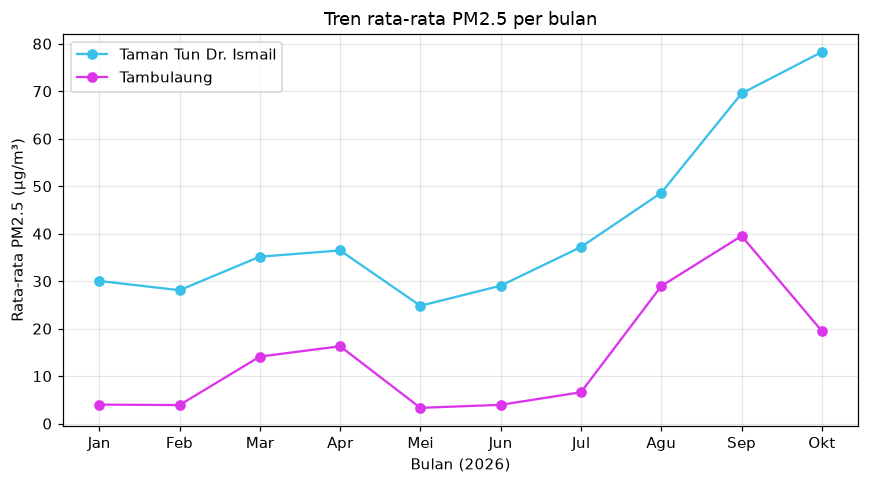

In [12]:
vis = (data.withColumn("ts_local", F.expr("ts + INTERVAL 8 HOURS"))
           .withColumn("bulan", F.month("ts_local"))
           .withColumn("jam", F.hour("ts_local")))
NAMA_BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

# Gambar 1: tren rata-rata PM2.5 per bulan per lokasi
bulanan = (vis.groupBy("bulan", "location_name").agg(F.avg("pm25").alias("rata_pm25"))
              .orderBy("bulan").toPandas())
display(bulanan.pivot(index="bulan", columns="location_name", values="rata_pm25").round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
for lok, g in bulanan.groupby("location_name"):
    ax.plot(g["bulan"], g["rata_pm25"], marker="o", label=lok, color=WARNA_LOKASI.get(lok))
bln = sorted(bulanan["bulan"].unique())
ax.set_xticks(bln)
ax.set_xticklabels([NAMA_BULAN[m - 1] for m in bln])
ax.set_xlabel("Bulan (2026)")
ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
ax.set_title("Tren rata-rata PM2.5 per bulan")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DIR_GAMBAR}/eda_1_tren_bulanan.png", dpi=150)
plt.show()

location_name,Taman Tun Dr. Ismail,Tambulaung
jam,,
0,45.3,15.1
1,44.8,14.5
2,43.7,14.4
3,43.4,14.0
4,42.2,13.8
5,40.8,13.9
6,40.8,14.5
7,40.8,14.3
8,41.0,14.1


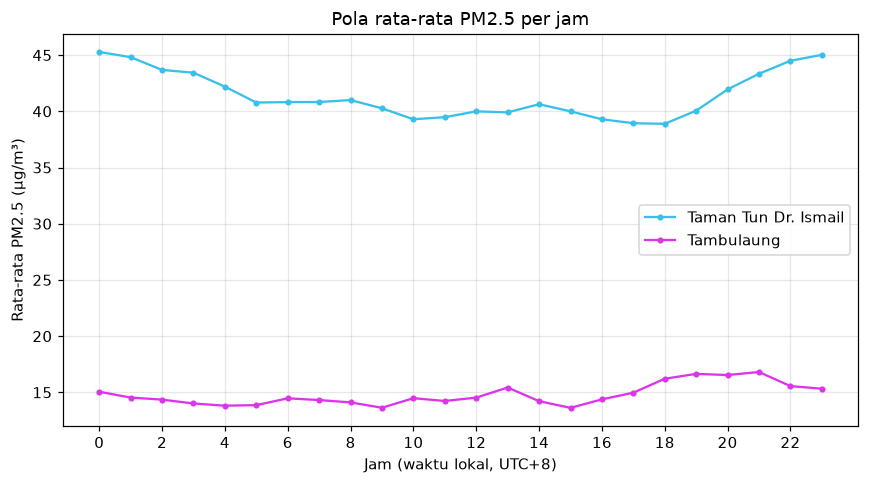

In [13]:
# Gambar 2: pola rata-rata PM2.5 per jam dalam sehari
per_jam = (vis.groupBy("jam", "location_name").agg(F.avg("pm25").alias("rata_pm25"))
              .orderBy("jam").toPandas())
display(per_jam.pivot(index="jam", columns="location_name", values="rata_pm25").round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
for lok, g in per_jam.groupby("location_name"):
    ax.plot(g["jam"], g["rata_pm25"], marker="o", markersize=3, label=lok, color=WARNA_LOKASI.get(lok))
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Jam (waktu lokal, UTC+8)")
ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
ax.set_title("Pola rata-rata PM2.5 per jam")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DIR_GAMBAR}/eda_2_pola_jam.png", dpi=150)
plt.show()

location_name,Taman Tun Dr. Ismail,Tambulaung
Baik,271,3566
Sedang,3080,2159
Tidak sehat (sensitif),2654,559
Tidak sehat,1003,140
Sangat tidak sehat,172,39
Berbahaya,0,0


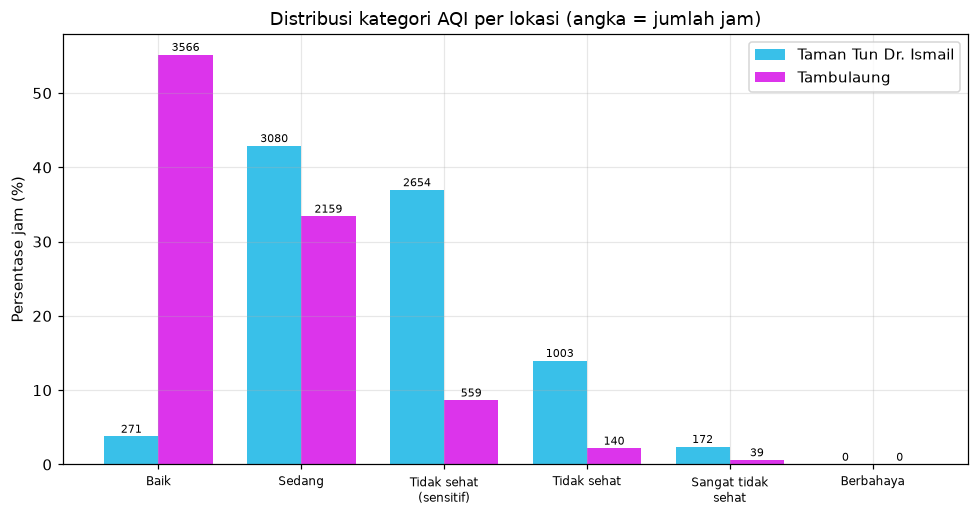

In [14]:
# Gambar 3: distribusi kategori AQI per lokasi (PM2.5, standar EPA versi terbaru)
KATEGORI = ["Baik", "Sedang", "Tidak sehat\n(sensitif)", "Tidak sehat", "Sangat tidak\nsehat", "Berbahaya"]
berlabel = (vis.filter(F.col("pm25").isNotNull())
               .withColumn("kategori",
                           F.when(F.col("pm25") <= 9.0, 0)
                            .when(F.col("pm25") <= 35.4, 1)
                            .when(F.col("pm25") <= 55.4, 2)
                            .when(F.col("pm25") <= 125.4, 3)
                            .when(F.col("pm25") <= 225.4, 4)
                            .otherwise(5)))
dist = berlabel.groupBy("location_name", "kategori").count().toPandas()
tabel = (dist.pivot(index="kategori", columns="location_name", values="count")
             .reindex(range(6)).fillna(0))
persen = tabel.div(tabel.sum(axis=0), axis=1) * 100
tabel.index = [k.replace("\n", " ") for k in KATEGORI]
display(tabel.astype(int))

fig, ax = plt.subplots(figsize=(9, 4.8))
lebar = 0.38
for i, lok in enumerate(persen.columns):
    xs = np.arange(6) + (i - 0.5) * lebar
    ax.bar(xs, persen[lok].values, width=lebar, label=lok, color=WARNA_LOKASI.get(lok))
    for x, p, n in zip(xs, persen[lok].values, tabel[lok].values):
        ax.text(x, p + 0.5, f"{int(n)}", ha="center", fontsize=7)
ax.set_xticks(range(6))
ax.set_xticklabels(KATEGORI, fontsize=8)
ax.set_ylabel("Persentase jam (%)")
ax.set_title("Distribusi kategori AQI per lokasi (angka = jumlah jam)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DIR_GAMBAR}/eda_3_distribusi_aqi.png", dpi=150)
plt.show()

,pm1,pm25,um003,temperature,relativehumidity
pm1,1.00,0.99,0.90,0.14,-0.09
pm25,0.99,1.00,0.93,0.12,-0.07
um003,0.90,0.93,1.00,0.07,-0.02
temperature,0.14,0.12,0.07,1.00,-0.86
relativehumidity,-0.09,-0.07,-0.02,-0.86,1.00


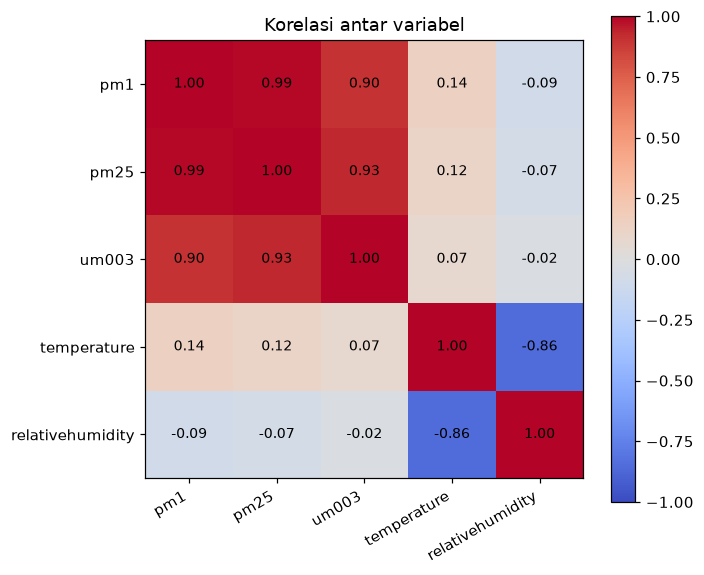

In [15]:
# Gambar 4: korelasi antar variabel (Pearson, dihitung dengan Spark MLlib, kedua lokasi digabung)
vec = VectorAssembler(inputCols=PARAMS, outputCol="v", handleInvalid="skip").transform(data)
mat = Correlation.corr(vec, "v").head()[0].toArray()
tabel_korelasi = pd.DataFrame(mat, index=PARAMS, columns=PARAMS).round(2)
display(tabel_korelasi)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(mat, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(PARAMS)))
ax.set_yticks(range(len(PARAMS)))
ax.set_xticklabels(PARAMS, rotation=30, ha="right")
ax.set_yticklabels(PARAMS)
ax.grid(False)
for i in range(len(PARAMS)):
    for j in range(len(PARAMS)):
        ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax)
ax.set_title("Korelasi antar variabel")
plt.tight_layout()
plt.savefig(f"{DIR_GAMBAR}/eda_4_korelasi.png", dpi=150)
plt.show()

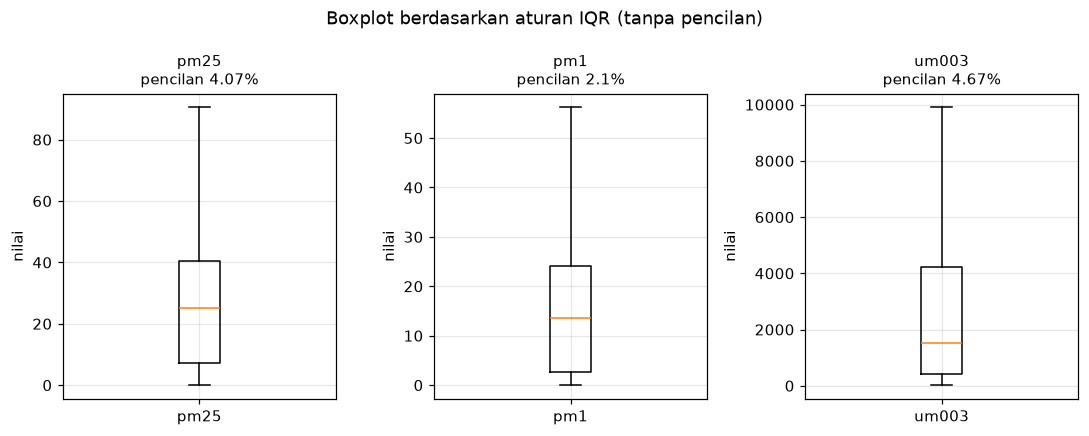

gambar tersimpan: ['eda_1_tren_bulanan.png', 'eda_2_pola_jam.png', 'eda_3_distribusi_aqi.png', 'eda_4_korelasi.png', 'eda_5_boxplot.png']


In [16]:
# Gambar 5: boxplot (batas IQR dihitung dengan Spark)
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
for ax, c in zip(axes, ["pm25", "pm1", "um003"]):
    persen_out = tabel_iqr.loc[tabel_iqr["variabel"] == c, "persen"].iloc[0]
    ax.bxp([stat_iqr[c]], showfliers=False)
    ax.set_title(f"{c}\npencilan {persen_out}%", fontsize=10)
    ax.set_ylabel("nilai")
plt.suptitle("Boxplot berdasarkan aturan IQR (tanpa pencilan)")
plt.tight_layout()
plt.savefig(f"{DIR_GAMBAR}/eda_5_boxplot.png", dpi=150)
plt.show()

print("gambar tersimpan:", sorted(os.listdir(DIR_GAMBAR)))